# Problema 2 - Regressão Logística: Previsão de Doenças Cardíacas

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FredGregorio/Disciplina-sistemas-inteligentes-2026.2/blob/main/Primeira%20Unidade/Projetos/02-regressao-logistica-heart-disease/src/problema2.ipynb)

## 1. Importando as bibliotecas e carregando os dados

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, roc_auc_score
)

plt.rcParams['figure.figsize'] = (8, 4)

In [2]:
# Se o arquivo existir na pasta do projeto, estamos rodando no PC.
# Se não existir (ex.: Google Colab), baixamos o mesmo arquivo do GitHub.
if os.path.exists("../data/heart_cleveland.csv"):
    caminho_dados = "../data/heart_cleveland.csv"
    pasta_resultados = "../resultados"
else:
    caminho_dados = "https://raw.githubusercontent.com/FredGregorio/Disciplina-sistemas-inteligentes-2026.2/main/Primeira%20Unidade/Projetos/02-regressao-logistica-heart-disease/data/heart_cleveland.csv"
    pasta_resultados = "resultados"

os.makedirs(pasta_resultados, exist_ok=True)   # pasta onde salvamos os gráficos

df = pd.read_csv(caminho_dados, na_values="?")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
print(f"Quantidade de pacientes = {df.shape[0]}")
print(f"Quantidade de colunas   = {df.shape[1]}")

Quantidade de pacientes = 303
Quantidade de colunas   = 14


## 2. Valores ausentes

In [4]:
print(df.isna().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


## 3. Binarização da variável alvo

In [5]:
print("Antes:", df["num"].value_counts().sort_index().to_dict())

df["target"] = (df["num"] > 0).astype(int)    # True/False vira 1/0
df = df.drop(columns=["num"])

print("Depois:", df["target"].value_counts().sort_index().to_dict())

Antes: {0: 164, 1: 55, 2: 36, 3: 35, 4: 13}
Depois: {0: 164, 1: 139}


## 4. Divisão em treino e teste

In [6]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]} pacientes")
print(f"Teste:  {X_test.shape[0]} pacientes")

Treino: 242 pacientes
Teste:  61 pacientes


## 5. Pré-processamento

### 5.1 Preenchendo os valores ausentes (moda do treino)

In [7]:
for coluna in ["ca", "thal"]:
    moda = X_train[coluna].mode()[0]          # valor mais frequente no treino
    X_train[coluna] = X_train[coluna].fillna(moda)
    X_test[coluna] = X_test[coluna].fillna(moda)
    print(f"{coluna}: ausentes preenchidos com a moda = {moda}")

print("\nAusentes restantes (treino):", int(X_train.isna().sum().sum()))
print("Ausentes restantes (teste): ", int(X_test.isna().sum().sum()))

ca: ausentes preenchidos com a moda = 0.0
thal: ausentes preenchidos com a moda = 3.0

Ausentes restantes (treino): 0
Ausentes restantes (teste):  0


### 5.2 Variáveis categóricas (one-hot encoding)

In [8]:
categoricas = ["cp", "restecg", "slope", "thal"]

X_train = pd.get_dummies(X_train, columns=categoricas, dtype=int)
X_test  = pd.get_dummies(X_test,  columns=categoricas, dtype=int)

# Garante que o teste tenha exatamente as mesmas colunas do treino
# (se alguma categoria não aparecer no teste, a coluna é criada com zeros)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f"Quantidade de features após o one-hot: {X_train.shape[1]}")
print(list(X_train.columns))

Quantidade de features após o one-hot: 22
['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'ca', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0']


### 5.3 Padronização (z-score)

In [9]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

## 6. Tarefa 1 - Treinando a regressão logística

In [10]:
model = LogisticRegression(solver='liblinear', random_state=42, max_iter=1000)
model.fit(X_train_sc, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [11]:
print(f"Iterações até a convergência: {model.n_iter_[0]}")
print(f"Limite máximo (max_iter):     {model.max_iter}")

Iterações até a convergência: 6
Limite máximo (max_iter):     1000


In [12]:
coef = pd.Series(model.coef_[0], index=X_train.columns).sort_values()
print(f"Intercepto (theta0): {model.intercept_[0]:.4f}\n")
print(coef.round(4))

Intercepto (theta0): -0.0702

thalach       -0.3444
cp_3.0        -0.3253
thal_3.0      -0.3249
slope_1.0     -0.2969
cp_1.0        -0.2934
restecg_1.0   -0.1376
thal_6.0      -0.1149
restecg_0.0   -0.0950
fbs           -0.0938
age           -0.0670
slope_3.0     -0.0607
cp_2.0         0.0144
restecg_2.0    0.1127
chol           0.1957
oldpeak        0.2047
exang          0.2661
slope_2.0      0.3281
trestbps       0.3684
thal_7.0       0.3791
cp_4.0         0.4341
sex            0.7459
ca             1.1706
dtype: float64


## 7. Tarefa 2 - Avaliação no conjunto de teste

In [13]:
y_pred = model.predict(X_test_sc)
y_prob = model.predict_proba(X_test_sc)[:, 1]    # probabilidade de ter doença

In [14]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

vn, fp, fn, vp = cm.ravel()
print(f"\nVerdadeiros negativos (sem doença, acertou): {vn}")
print(f"Falsos positivos (sem doença, previu doença): {fp}")
print(f"Falsos negativos (com doença, previu sem):    {fn}")
print(f"Verdadeiros positivos (com doença, acertou):  {vp}")

[[27  6]
 [ 4 24]]

Verdadeiros negativos (sem doença, acertou): 27
Falsos positivos (sem doença, previu doença): 6
Falsos negativos (com doença, previu sem):    4
Verdadeiros positivos (com doença, acertou):  24


In [15]:
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisão: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:   {recall_score(y_test, y_pred):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred):.4f}")

Acurácia: 0.8361
Precisão: 0.8000
Recall:   0.8571
F1-score: 0.8276


AUC = 0.9394


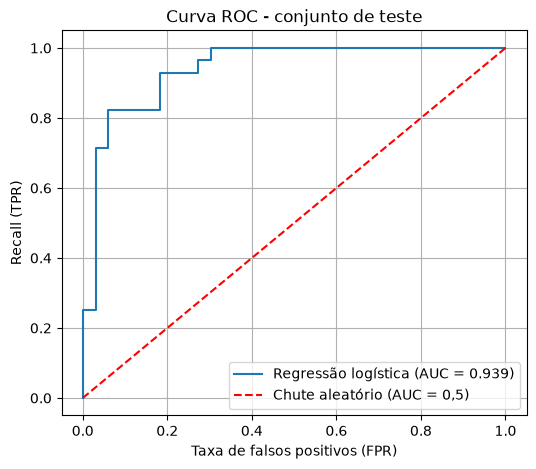

In [16]:
fpr, tpr, limiares = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
print(f"AUC = {auc:.4f}")

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Regressão logística (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'r--', label="Chute aleatório (AUC = 0,5)")
plt.xlabel("Taxa de falsos positivos (FPR)")
plt.ylabel("Recall (TPR)")
plt.title("Curva ROC - conjunto de teste")
plt.legend()
plt.grid()
plt.savefig(f"{pasta_resultados}/curva_roc.png", dpi=150)
plt.show()

## 8. Conclusão